# 03 · Shipment-level characteristics vs delay risk

**Question:** which attributes known at booking/departure (priority, carrier, mode, cargo, TEU, ports, route, departure
time, planned transit duration) distinguish On-Time, At-Risk and Critical shipments — and are those differences
genuine or explained by other attributes (confounding)?

Air shipments are always On-Time (notebook 02), so effects are measured on **sea shipments** unless stated.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as ss

from cargomind_eda import io, stats, plotting as P
from cargomind_eda.config import CLASSES, CLASS_COLORS, THRESHOLDS

P.setup()
s = io.load("shipment_records")
net = io.load("port_network")
meta = io.load("port_metadata")
s = s.merge(net[["route_id", "route_type", "transshipment_port_id", "route_distance_km", "planned_transit_hours"]], on="route_id", validate="m:1")
s["planned_duration_h"] = (s.expected_arrival_ts - s.departure_ts).dt.total_seconds() / 3600
tz = meta.set_index("port_id").local_timezone
s["dep_hour_local"] = [ts.tz_convert(tz[p]).hour for ts, p in zip(s.departure_ts, s.origin_port_id)]
s["dep_dow"] = s.departure_ts.dt.day_name().str[:3]
s["delayed"] = (s.delay_status != "On-Time").astype(int)
sea = s[s.shipping_mode == "sea"].copy()
print(s.shape, sea.shape)

(9850, 24) (9347, 24)


## C1. Shipping mode — a deterministic split

In [2]:
print(s.groupby("shipping_mode").actual_delay_hours.describe().round(2))
air = s[s.shipping_mode == "air"]
print("\nair planned duration / route planned hours:", (air.planned_duration_h / air.planned_transit_hours).describe().round(3).to_dict())
print("air shipments by route_type:", air.route_type.value_counts().to_dict())

               count  mean   std   min  25%  50%  75%  max
shipping_mode                                             
air              503 -3.68  1.58  -7.1 -4.8   -4 -2.8  3.4
sea            9,347 19.53 29.78 -29.4 -2.5 10.3 33.2  201

air planned duration / route planned hours: {'count': 503.0, 'mean': 0.146, 'std': 0.134, 'min': 0.066, '25%': 0.087, '50%': 0.108, '75%': 0.148, 'max': 0.812}
air shipments by route_type: {'direct': 304, 'transshipment': 199}


All 503 air shipments are On-Time (max delay 3.4 h), and their planned duration is ~7–80 % of the sea route's planned
hours. `shipping_mode` is therefore a perfect On-Time predictor for air. A model needs no learning for these rows; they
can be handled by a rule or kept in training with the caveat that they inflate apparent accuracy. All further analysis
uses sea shipments.

## C2. Categorical attributes: association strength
Chi-square of independence with bias-corrected Cramér's V. All expected cell counts ≥ 5 unless noted.

In [3]:
sea["dep_hour_bucket"] = pd.cut(sea.dep_hour_local, [-1, 5, 11, 17, 23], labels=["00–05", "06–11", "12–17", "18–23"])
cats = ["carrier", "cargo_type", "shipment_priority", "origin_port_id", "destination_port_id", "route_id", "route_type", "dep_dow", "dep_hour_bucket"]
cat_tab = stats.screen_categorical(sea, cats).sort_values("cramers_v", ascending=False)
cat_tab["magnitude"] = cat_tab.cramers_v.map(lambda v: stats.magnitude_label(v, "v"))
P.save_table(cat_tab, "03_categorical_association_sea")
cat_tab

,levels,chi2,dof,p_value,cramers_v,min_expected,pct_cells_expected_lt5,magnitude
feature,,,,,,,,
route_id,90,"1,074",178,7.535e-128,0.2189,3.16,1.481,small
route_type,2,320.9,2,2.096e-70,0.1847,549.7,0,small
origin_port_id,10,509.4,18,1.102e-96,0.1621,64.63,0,small
carrier,6,258.7,10,8.166e-50,0.1153,171.9,0,small
shipment_priority,3,130.8,4,2.672e-27,0.08236,292,0,negligible
destination_port_id,10,135.2,18,5.483e-20,0.07917,72.53,0,negligible
cargo_type,3,102.5,4,2.833e-21,0.07261,102.4,0,negligible
dep_dow,7,53.52,12,3.334e-07,0.04713,179,0,negligible
dep_hour_bucket,4,8.616,6,0.1963,0.01183,362.8,0,negligible


`route_id` has the largest V but 90 levels, so part of its V is capacity to fit noise; it decomposes into origin,
destination and route type (notebook 06). Departure hour shows **no association** (V = 0.01, p = 0.20). Day-of-week is
statistically detectable but negligible (V = 0.05); with only ~6 weeks of data, each weekday has ~6 dates, so this most
likely reflects which dates had disruptions rather than a weekly cycle.

## C3. Numeric attributes: TEU, planned duration, distance, departure hour

In [4]:
nums = ["container_teu", "planned_duration_h", "route_distance_km", "planned_transit_hours", "dep_hour_local"]
num_tab = stats.screen_numeric(sea, nums).sort_values("epsilon_sq", ascending=False)
P.save_table(num_tab, "03_numeric_association_sea")
num_tab.round(4)

,n,tie_share,kruskal_H,p_value,epsilon_sq,median_On-Time,median_At-Risk,median_Critical,cliff_At-Risk_vs_On-Time,cliff_Critical_vs_On-Time,cliff_Critical_vs_At-Risk,spearman_rho_delay_h,spearman_p
feature,,,,,,,,,,,,,
planned_duration_h,9347,0.0509,112.1,0,0.012,225,240,305,0.0534,0.1814,0.1256,0.0787,0
planned_transit_hours,9347,0.0509,112,0,0.012,225,239.9,305.1,0.0533,0.1813,0.1256,0.0786,0
route_distance_km,9347,0.0509,73.07,0,0.0078,"6,634","6,610","8,170",0.0323,0.1469,0.1129,0.0532,0
dep_hour_local,9347,0.0456,6.665,0.0357,0.0007,11,12,11,0.0212,-0.0251,-0.047,-0.0002,0.9872
container_teu,9347,0.0637,0.2221,0.8949,0,10,10,10,0.0021,0.0081,0.0057,0.0028,0.788


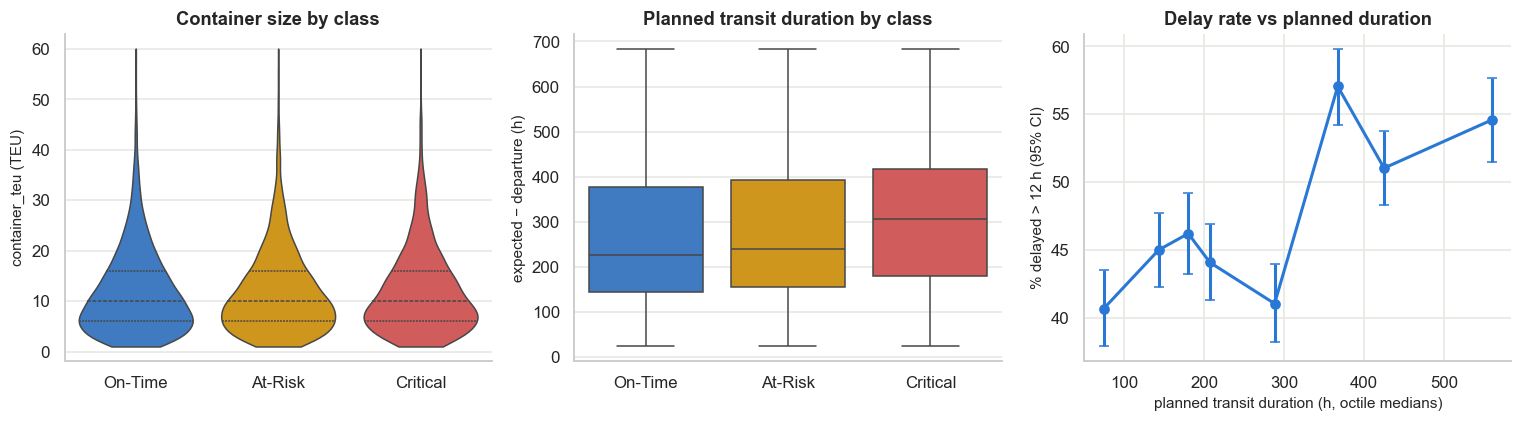

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.violinplot(data=sea, x="delay_status", y="container_teu", hue="delay_status", legend=False, order=CLASSES, palette=CLASS_COLORS, ax=axes[0], cut=0, inner="quartile", linewidth=1)
axes[0].set_title("Container size by class")
axes[0].set_ylabel("container_teu (TEU)")
sns.boxplot(data=sea, x="delay_status", y="planned_duration_h", hue="delay_status", legend=False, order=CLASSES, palette=CLASS_COLORS, ax=axes[1], fliersize=1, linewidth=1)
axes[1].set_title("Planned transit duration by class")
axes[1].set_ylabel("expected − departure (h)")
b = pd.qcut(sea.planned_duration_h, 8)
rate = sea.groupby(b, observed=True).agg(p=("delayed", "mean"), n=("delayed", "size"), x=("planned_duration_h", "median"))
ci = np.array([stats.wilson_ci(p * n, n) for p, n in zip(rate.p, rate.n)])
axes[2].errorbar(rate.x, rate.p * 100, yerr=[(rate.p - ci[:, 0]) * 100, (ci[:, 1] - rate.p) * 100], fmt="o-", color="#2a78d6", capsize=3)
axes[2].set_xlabel("planned transit duration (h, octile medians)")
axes[2].set_ylabel("% delayed > 12 h (95% CI)")
axes[2].set_title("Delay rate vs planned duration")
for a in axes[:2]:
    a.set_xlabel("")
P.save(fig, "03_teu_duration")

* **Container TEU**: medians are identical across classes and ε² ≈ 0 — no evidence that shipment size relates to delay risk.
* **Planned duration / distance**: a weak, non-monotonic association (ε² small). Longer voyages are not simply riskier;
  the shape is driven by which origins/route types sit in each duration band (see C5 and notebook 06).
* **Departure hour (local)**: no association.

## C4. Priority, cargo type and carrier — ordered effects

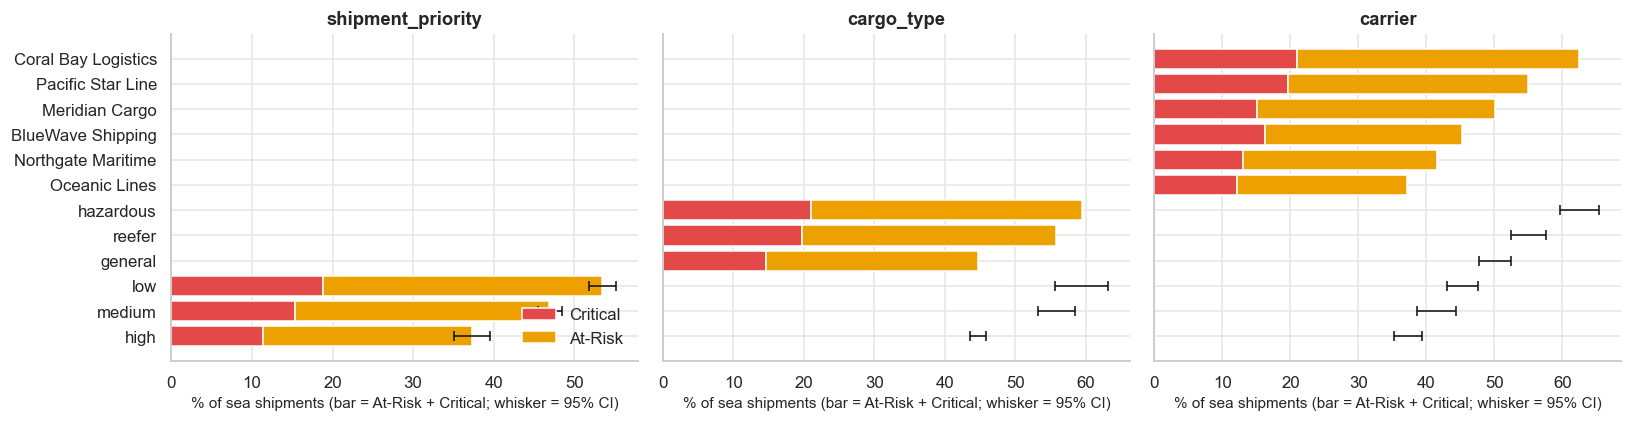

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, c in zip(axes, ["shipment_priority", "cargo_type", "carrier"]):
    r = stats.class_rates(sea, c).sort_values("pct_delayed(>12h)")
    ax.barh(r.index.astype(str), r["pct_Critical"], color=CLASS_COLORS["Critical"], label="Critical")
    ax.barh(r.index.astype(str), r["pct_At-Risk"], left=r["pct_Critical"], color=CLASS_COLORS["At-Risk"], label="At-Risk")
    ax.errorbar(r["pct_delayed(>12h)"], range(len(r)), xerr=[r["pct_delayed(>12h)"] - r.ci95_low, r.ci95_high - r["pct_delayed(>12h)"]], fmt="none", ecolor="#0b0b0b", capsize=3, lw=1)
    ax.set_title(c)
    ax.set_xlabel("% of sea shipments (bar = At-Risk + Critical; whisker = 95% CI)")
axes[0].legend(loc="lower right")
P.save(fig, "03_priority_cargo_carrier")

## C5. Confounding check: is the carrier effect just a route-mix effect?

Carriers serve different route mixes. If high-delay carriers simply sail more often from high-delay origins, the raw carrier
gap would overstate a carrier effect. **Indirect standardisation**: for each carrier, compute the expected delay rate given
its own route mix (using all-carrier route delay rates) and compare with the observed rate. The same is done for priority
and cargo type.

In [7]:
def standardised(df, group, stratum="route_id", outcome="delayed"):
    base = df.groupby(stratum)[outcome].mean()
    exp = df[stratum].map(base)
    out = df.assign(_exp=exp).groupby(group, observed=True).agg(n=(outcome, "size"), observed=(outcome, "mean"), expected_from_route_mix=("_exp", "mean"))
    out["obs_minus_exp_pp"] = (out.observed - out.expected_from_route_mix) * 100
    out["obs/exp"] = out.observed / out.expected_from_route_mix
    return (out.assign(observed=out.observed * 100, expected_from_route_mix=out.expected_from_route_mix * 100)).round(2)

for g in ["carrier", "shipment_priority", "cargo_type"]:
    print(f"\n── {g}")
    display(standardised(sea, g))


── carrier


,n,observed,expected_from_route_mix,obs_minus_exp_pp,obs/exp
carrier,,,,,
BlueWave Shipping,1812,45.25,47.62,-2.37,0.95
Coral Bay Logistics,1088,62.59,47.24,15.35,1.32
Meridian Cargo,1694,50.12,47,3.11,1.07
Northgate Maritime,1166,41.42,47.25,-5.83,0.88
Oceanic Lines,2124,37.19,47.58,-10.38,0.78
Pacific Star Line,1463,55.02,47.39,7.64,1.16



── shipment_priority


,n,observed,expected_from_route_mix,obs_minus_exp_pp,obs/exp
shipment_priority,,,,,
low,3321,53.51,47.3,6.21,1.13
medium,4178,46.96,47.53,-0.57,0.99
high,1848,37.28,47.16,-9.87,0.79



── cargo_type


,n,observed,expected_from_route_mix,obs_minus_exp_pp,obs/exp
cargo_type,,,,,
general,7292,44.68,47.22,-2.54,0.95
hazardous,648,59.41,48.11,11.3,1.23
reefer,1407,55.79,47.84,7.95,1.17


In [8]:
# Is the carrier/priority/cargo assignment itself route-dependent?
print("Cramér's V between carrier and route_id :", round(stats.cramers_v(pd.crosstab(sea.carrier, sea.route_id)), 3))
print("Cramér's V between carrier and origin   :", round(stats.cramers_v(pd.crosstab(sea.carrier, sea.origin_port_id)), 3))
print("Cramér's V between priority and carrier :", round(stats.cramers_v(pd.crosstab(sea.shipment_priority, sea.carrier)), 3))
print("Cramér's V between cargo and carrier    :", round(stats.cramers_v(pd.crosstab(sea.cargo_type, sea.carrier)), 3))

Cramér's V between carrier and route_id : 0.0
Cramér's V between carrier and origin   : 0.0
Cramér's V between priority and carrier : 0.019
Cramér's V between cargo and carrier    : 0.0


**Result:** carrier, cargo type and priority are statistically independent of route and origin (Cramér's V ≈ 0), so the
route mix explains none of their gaps — observed and route-mix-expected rates differ by up to 15 pp (Coral Bay +15 pp,
Oceanic −10 pp; high priority −10 pp; hazardous +11 pp). These attributes carry information that is *additional* to route.

## C6. Effects within route type (stratified)

route_type,direct,transshipment
carrier,,
Oceanic Lines,32.3,44.9
Northgate Maritime,35.2,52.4
BlueWave Shipping,37.8,57.6
Meridian Cargo,43.7,61.8
Pacific Star Line,46.4,69.8
Coral Bay Logistics,54.9,75.4


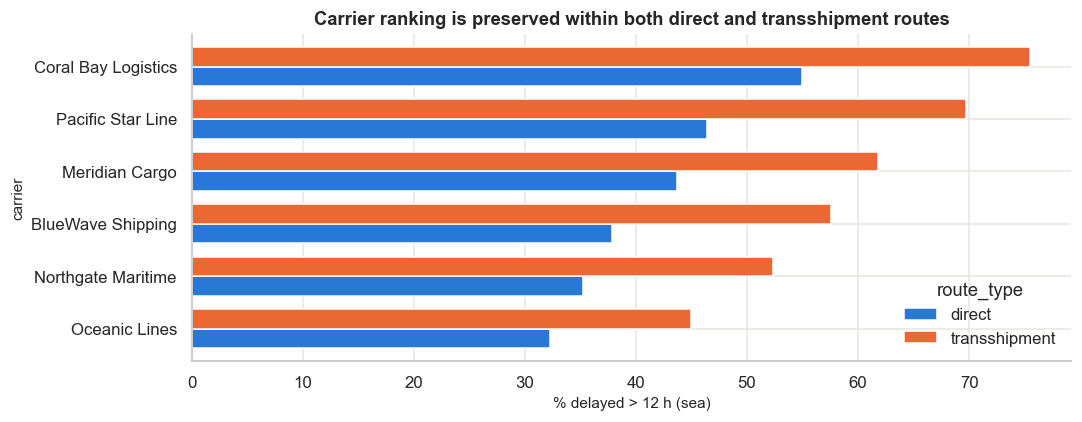

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
tab = sea.groupby(["carrier", "route_type"]).delayed.mean().unstack() * 100
tab = tab.loc[tab.mean(1).sort_values().index]
tab.plot.barh(ax=ax, color=["#2a78d6", "#eb6834"], width=0.75)
ax.set_xlabel("% delayed > 12 h (sea)")
ax.set_title("Carrier ranking is preserved within both direct and transshipment routes")
ax.legend(title="route_type")
P.save(fig, "03_carrier_by_route_type")
tab.round(1)

## C7. Departure timing

daily share delayed: min 25.7%, max 75.9%, sd 12.6 pp (days with ≥50 departures: 41)


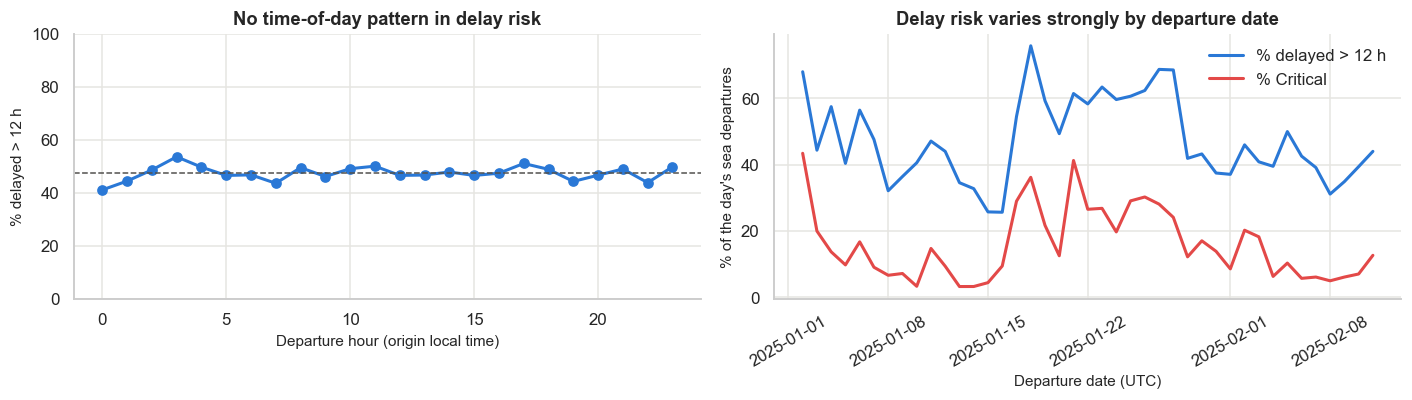

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
h = sea.groupby("dep_hour_local").delayed.agg(["mean", "size"])
axes[0].plot(h.index, h["mean"] * 100, marker="o", color="#2a78d6")
axes[0].axhline(sea.delayed.mean() * 100, color="#52514e", ls="--", lw=1)
axes[0].set_xlabel("Departure hour (origin local time)")
axes[0].set_ylabel("% delayed > 12 h")
axes[0].set_ylim(0, 100)
axes[0].set_title("No time-of-day pattern in delay risk")
daily = sea.groupby(sea.departure_ts.dt.date).agg(rate=("delayed", "mean"), crit=("delay_status", lambda x: (x == "Critical").mean()), n=("delayed", "size"))
axes[1].plot(daily.index, daily.rate * 100, color="#2a78d6", label="% delayed > 12 h")
axes[1].plot(daily.index, daily.crit * 100, color="#e34948", label="% Critical")
axes[1].set_ylabel("% of the day's sea departures")
axes[1].set_xlabel("Departure date (UTC)")
axes[1].set_title("Delay risk varies strongly by departure date")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=30)
P.save(fig, "03_departure_timing")
print(f"daily share delayed: min {daily.rate.min()*100:.1f}%, max {daily.rate.max()*100:.1f}%, sd {daily.rate.std()*100:.1f} pp (days with ≥50 departures: {(daily.n >= 50).sum()})")

Clock time does not matter, but **calendar date** matters a lot: the daily delay rate swings widely. Something time-varying
and shared across shipments drives risk — port conditions, weather and disruptions (notebooks 04–08). This is also the
main argument for a time-based train/test split.

## C8. Summary — shipment-level attributes

| Attribute | Evidence (sea) | Assessment |
|---|---|---|
| shipping_mode | air = 100 % On-Time | deterministic; handle by rule or flag |
| origin_port_id | V ≈ 0.16; delayed share 31 % (MYPKG) → 68 % (NLRTM) | strongest static attribute; likely proxies port conditions |
| carrier | V ≈ 0.12; 37 % → 63 %; independent of route (V≈0), ranking holds within direct and transshipment | genuine carrier-level difference *in this data* |
| shipment_priority | V ≈ 0.08; high 37 % vs low 54 % | monotone, modest |
| cargo_type | V ≈ 0.07; hazardous / reefer above general | modest |
| destination_port_id | V ≈ 0.08 | weaker than origin |
| route_type | V ≈ 0.18; transshipment riskier for every carrier | strong, structural |
| planned duration / distance | ε² ≈ 0.01; Critical median 305 h vs 225 h | weak; largely via route type |
| container_teu | ε² ≈ 0 | no evidence of association |
| departure hour / weekday | hour V = 0.01 (n.s.); weekday V = 0.05 | no useful association |
| departure date | daily delay rate swings strongly | points to time-varying operational drivers |

Associations are observational. A carrier effect that survives route-mix adjustment may still reflect unmeasured
differences (vessel quality, schedules, booking behaviour), so it should not be read as causal.